In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

import os

for folder, subfolders, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(folder, filename))


/kaggle/input/datasets/anulekhaadhikary/online-retail-raw-dataset/Online Retail.xlsx


In [3]:

import pandas as pd
import numpy as np

file_path = "/kaggle/input/datasets/anulekhaadhikary/online-retail-raw-dataset/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Number of rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
C

In [5]:

# Inspect unusual records before cleaning

print("Negative quantities:", (df["Quantity"] < 0).sum())

print("Zero quantities:", (df["Quantity"] == 0).sum())

print("Zero or negative prices:", (df["UnitPrice"] <= 0).sum())

print("Cancelled invoices:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Blank descriptions:",
      df["Description"].isna().sum())

print("Exact duplicate rows:", df.duplicated().sum())

print("\nSample cancelled transactions:")
print(
    df[df["InvoiceNo"].astype(str).str.startswith("C")].head()
)


Negative quantities: 10624
Zero quantities: 0
Zero or negative prices: 2517
Cancelled invoices: 9288
Blank descriptions: 1454
Exact duplicate rows: 5268

Sample cancelled transactions:
    InvoiceNo StockCode                       Description  Quantity  \
141   C536379         D                          Discount        -1   
154   C536383    35004C   SET OF 3 COLOURED  FLYING DUCKS        -1   
235   C536391     22556    PLASTERS IN TIN CIRCUS PARADE        -12   
236   C536391     21984  PACK OF 12 PINK PAISLEY TISSUES        -24   
237   C536391     21983  PACK OF 12 BLUE PAISLEY TISSUES        -24   

            InvoiceDate  UnitPrice  CustomerID         Country  
141 2010-12-01 09:41:00      27.50     14527.0  United Kingdom  
154 2010-12-01 09:49:00       4.65     15311.0  United Kingdom  
235 2010-12-01 10:24:00       1.65     17548.0  United Kingdom  
236 2010-12-01 10:24:00       0.29     17548.0  United Kingdom  
237 2010-12-01 10:24:00       0.29     17548.0  United Kingdom 

In [6]:

# Keep the original dataset unchanged
clean_df = df.copy()

# 1. Remove exact duplicate rows
clean_df = clean_df.drop_duplicates().copy()

# 2. Standardize product descriptions and country names
clean_df["Description"] = clean_df["Description"].str.strip()
clean_df["Country"] = clean_df["Country"].str.strip()

# 3. Convert CustomerID to a nullable integer
clean_df["CustomerID"] = clean_df["CustomerID"].astype("Int64")

# 4. Create a sales value field
clean_df["SalesValue"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

# 5. Identify cancelled invoices
clean_df["IsCancellation"] = (
    clean_df["InvoiceNo"].astype(str).str.startswith("C")
)

# 6. Flag unusual records instead of deleting them
clean_df["MissingCustomerID"] = clean_df["CustomerID"].isna()
clean_df["MissingDescription"] = clean_df["Description"].isna()
clean_df["NonPositivePrice"] = clean_df["UnitPrice"] <= 0
clean_df["NonPositiveQuantity"] = clean_df["Quantity"] <= 0

# 7. Create useful date fields
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"], errors="coerce"
)
clean_df["YearMonth"] = clean_df["InvoiceDate"].dt.to_period("M").astype(str)

print("Original shape:", df.shape)
print("Cleaned shape:", clean_df.shape)
print("Remaining exact duplicates:", clean_df.duplicated().sum())

clean_df.head()


Original shape: (541909, 8)
Cleaned shape: (536641, 15)
Remaining exact duplicates: 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue,IsCancellation,MissingCustomerID,MissingDescription,NonPositivePrice,NonPositiveQuantity,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False,False,False,False,False,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,False,False,False,False,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False,False,False,False,False,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,False,False,False,False,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,False,False,False,False,2010-12


In [7]:

# Save the cleaned dataset as a CSV file
output_file = "Online_Retail_Processed.csv"

clean_df.to_csv(output_file, index=False)

print("Processed file saved:", output_file)


Processed file saved: Online_Retail_Processed.csv


In [8]:

from IPython.display import display
from IPython.display import FileLink

display(FileLink("Online_Retail_Processed.csv"))


/kaggle/working/Online_Retail_Processed.csv

In [9]:

print("Original rows:", len(df))
print("Processed rows:", len(clean_df))
print("Rows removed as exact duplicates:", len(df) - len(clean_df))

print("\nMissing values after cleaning:")
print(clean_df.isnull().sum())

print("\nCancellation records:", clean_df["IsCancellation"].sum())
print("Negative quantity records:", (clean_df["Quantity"] < 0).sum())
print("Non-positive unit price records:", (clean_df["UnitPrice"] <= 0).sum())

print("\nFirst five processed records:")
display(clean_df.head())


Original rows: 541909
Processed rows: 536641
Rows removed as exact duplicates: 5268

Missing values after cleaning:
InvoiceNo                   0
StockCode                   0
Description              1455
Quantity                    0
InvoiceDate                 0
UnitPrice                   0
CustomerID             135037
Country                     0
SalesValue                  0
IsCancellation              0
MissingCustomerID           0
MissingDescription          0
NonPositivePrice            0
NonPositiveQuantity         0
YearMonth                   0
dtype: int64

Cancellation records: 9251
Negative quantity records: 10587
Non-positive unit price records: 2512

First five processed records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesValue,IsCancellation,MissingCustomerID,MissingDescription,NonPositivePrice,NonPositiveQuantity,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,False,False,False,False,False,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,False,False,False,False,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,False,False,False,False,False,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,False,False,False,False,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,False,False,False,False,False,2010-12


In [10]:

# Check descriptions that are empty or contain only spaces
blank_descriptions = (
    clean_df["Description"].notna()
    & clean_df["Description"].str.strip().eq("")
)

print("Empty descriptions:", blank_descriptions.sum())
print("Missing descriptions:", clean_df["Description"].isna().sum())


Empty descriptions: 0
Missing descriptions: 1455


In [11]:
# Prepare a sales analysis dataset
sales_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0) &
    (~clean_df["IsCancellation"])
].copy()

print("Rows available for positive-sales analysis:", len(sales_df))
print("Total sales value:", round(sales_df["SalesValue"].sum(), 2))
print("Unique products:", sales_df["StockCode"].nunique())
print("Unique countries:", sales_df["Country"].nunique())
print("Unique identified customers:", sales_df["CustomerID"].nunique())

Rows available for positive-sales analysis: 524878
Total sales value: 10642110.8
Unique products: 3922
Unique countries: 38
Unique identified customers: 4338


In [12]:

# Top 10 products by positive sales value

top_products = (
    sales_df.groupby("Description", dropna=False)
    .agg(
        Total_Sales=("SalesValue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

print("Top 10 products by sales value:")
display(top_products.round(2))


Top 10 products by sales value:


,Total_Sales,Units_Sold
Description,,
DOTCOM POSTAGE,206248.77,706
REGENCY CAKESTAND 3 TIER,174156.54,13851
"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872
PARTY BUNTING,99445.23,18283
JUMBO BAG RED RETROSPOT,94159.81,48371
MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033
POSTAGE,78101.88,3150
Manual,77752.82,6985


In [13]:

# Top 10 countries by positive sales value

top_countries = (
    sales_df.groupby("Country")
    .agg(
        Total_Sales=("SalesValue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

print("Top 10 countries by sales value:")
display(top_countries.round(2))


Top 10 countries by sales value:


,Total_Sales,Units_Sold,Invoice_Count
Country,,,
United Kingdom,9001744.09,4646906,18019
Netherlands,285446.34,200361,94
EIRE,283140.52,147007,288
Germany,228678.40,119154,457
France,209625.37,112060,392
Australia,138453.81,83891,57
Spain,61558.56,27933,90
Switzerland,57067.60,30617,54
Belgium,41196.34,23237,98


,Total_Sales,Units_Sold,Invoice_Count
YearMonth,,,
2010-12,821452.73,358019,1559
2011-01,689811.61,387099,1086
2011-02,522545.56,282934,1100
2011-03,716215.26,376599,1454
2011-04,536968.49,307953,1246
2011-05,769296.61,395001,1681
2011-06,760547.01,388511,1533
2011-07,718076.12,399693,1475
2011-08,757841.38,421020,1361


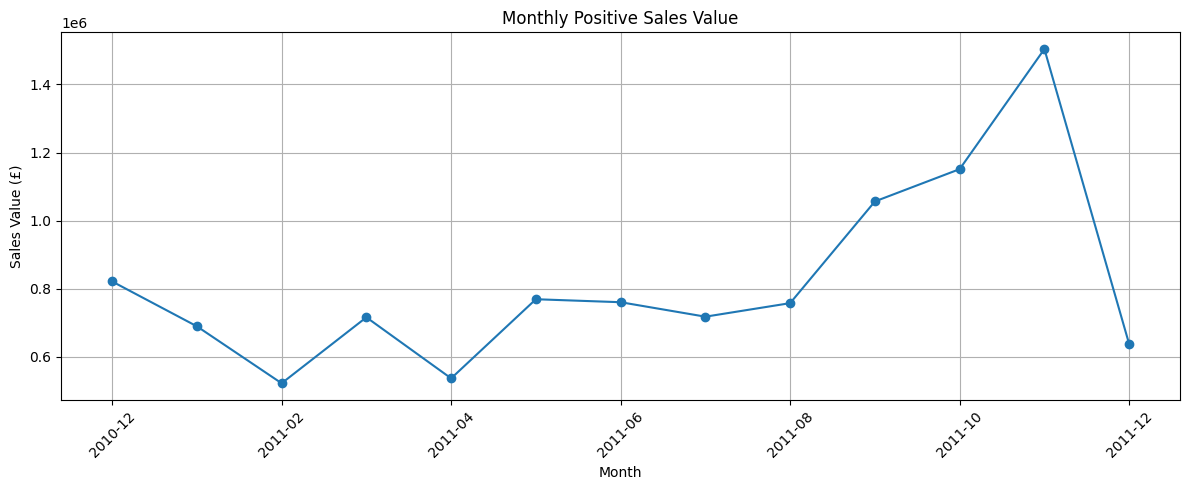

In [14]:

# Monthly sales trend
monthly_sales = (
    sales_df.groupby("YearMonth")
    .agg(
        Total_Sales=("SalesValue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .sort_index()
)

display(monthly_sales.round(2))

# Visualize the trend
monthly_sales["Total_Sales"].plot(
    kind="line",
    marker="o",
    figsize=(12, 5),
    title="Monthly Positive Sales Value"
)

plt.xlabel("Month")
plt.ylabel("Sales Value (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [15]:

customer_sales = (
    sales_df.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Total_Sales=("SalesValue", "sum"),
        Invoice_Count=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(customer_sales.head(10).round(2))
print("Total identified customers:", len(customer_sales))


,Total_Sales,Invoice_Count,Units_Sold
CustomerID,,,
14646,280206.02,73,196915
18102,259657.30,60,64124
17450,194390.79,46,69973
16446,168472.50,2,80997
14911,143711.17,201,80240
12415,124914.53,21,77374
14156,117210.08,55,57768
17511,91062.38,31,64549
16029,80850.84,63,40108


Total identified customers: 4338


In [17]:

cancelled = clean_df[clean_df["IsCancellation"]].copy()
negative_qty = clean_df[clean_df["Quantity"] < 0].copy()

print("Cancelled invoice rows:", len(cancelled))
print("Negative-quantity rows:", len(negative_qty))

print("\nTop countries by cancellation rows:")
display(cancelled.groupby("Country").size()
        .sort_values(ascending=False).head(10))

print("\nTop countries by negative-quantity rows:")
display(negative_qty.groupby("Country").size()
        .sort_values(ascending=False).head(10))


Cancelled invoice rows: 9251
Negative-quantity rows: 10587

Top countries by cancellation rows:


Country
United Kingdom    7821
Germany            453
EIRE               301
France             148
USA                112
Australia           74
Spain               48
Italy               45
Belgium             38
Japan               37
dtype: int64


Top countries by negative-quantity rows:


Country
United Kingdom    9157
Germany            453
EIRE               301
France             148
USA                112
Australia           74
Spain               48
Italy               45
Belgium             38
Japan               37
dtype: int64

In [18]:

print("Top 10 identified customers by sales value:")
display(customer_sales.head(10).round(2))

# Calculate the share of sales contributed by the top 10 customers
top10_sales = customer_sales.head(10)["Total_Sales"].sum()
identified_sales = customer_sales["Total_Sales"].sum()

print("Top 10 customer sales:", round(top10_sales, 2))
print("Identified customer sales:", round(identified_sales, 2))
print("Top 10 share (%):", round(top10_sales / identified_sales * 100, 2))


Top 10 identified customers by sales value:


,Total_Sales,Invoice_Count,Units_Sold
CustomerID,,,
14646,280206.02,73,196915
18102,259657.30,60,64124
17450,194390.79,46,69973
16446,168472.50,2,80997
14911,143711.17,201,80240
12415,124914.53,21,77374
14156,117210.08,55,57768
17511,91062.38,31,64549
16029,80850.84,63,40108


Top 10 customer sales: 1537659.21
Identified customer sales: 8887208.89
Top 10 share (%): 17.3


In [19]:

# Investigate the surprising DOTCOM POSTAGE result

product_check = (
    sales_df.groupby("Description", dropna=False)
    .agg(
        Total_Sales=("SalesValue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Average_Unit_Price=("UnitPrice", "mean"),
        Transaction_Lines=("InvoiceNo", "count")
    )
    .sort_values("Total_Sales", ascending=False)
)

print("Top 10 entries by sales value:")
display(product_check.head(10).round(2))

print("\nDOTCOM POSTAGE transaction sample:")
display(
    sales_df[
        sales_df["Description"].eq("DOTCOM POSTAGE")
    ][["InvoiceNo", "Quantity", "UnitPrice", "SalesValue"]].head(10)
)


Top 10 entries by sales value:


,Total_Sales,Units_Sold,Average_Unit_Price,Transaction_Lines
Description,,,,
DOTCOM POSTAGE,206248.77,706,292.14,706
REGENCY CAKESTAND 3 TIER,174156.54,13851,13.98,2007
"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,2.08,1
WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,3.22,2311
PARTY BUNTING,99445.23,18283,5.80,1699
JUMBO BAG RED RETROSPOT,94159.81,48371,2.49,2109
MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,1.47,250
POSTAGE,78101.88,3150,31.08,1126
Manual,77752.82,6985,233.76,317



DOTCOM POSTAGE transaction sample:


,InvoiceNo,Quantity,UnitPrice,SalesValue
1814,536544,1,569.77,569.77
3041,536592,1,607.49,607.49
5450,536862,1,254.43,254.43
5545,536864,1,121.06,121.06
5685,536865,1,498.47,498.47
6165,536876,1,887.52,887.52
10812,537237,1,863.74,863.74
11381,537240,1,940.87,940.87
13924,537434,1,950.99,950.99
15650,537638,1,836.14,836.14
